<a href="https://colab.research.google.com/github/hugolo000/DigitalImage_PROJECT/blob/main/notebooks/05_classical_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 - Classical segmentation (no deep learning)
Notebook 03 segments CamVid with a U-Net. To compare segmentation methods (our project topic), we need a classical method evaluated **in exactly the same conditions**: same 233 test images, same 256x256 size, same mIoU and confusion matrix.

This notebook has two parts:
- **Part A** tries the Lecture 08 methods (thresholds, Canny) to show why they cannot solve this task. It motivates Part B.
- **Part B** is the classical method we compare with the U-Net: the image is cut into superpixels, each superpixel is described by hand-crafted features, and a Random Forest predicts its class.



## 1. Setup and data
Same CamVid download as notebooks 01-03, so we work on exactly the same files.

In [ ]:
import time
import zipfile
import urllib.request
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from skimage.segmentation import slic, mark_boundaries     # superpixels
from skimage.feature import local_binary_pattern           # texture (LBP)
from sklearn.ensemble import RandomForestClassifier        # classifier

# Dataset source and folders
DATASET_URL = "https://github.com/alexgkendall/SegNet-Tutorial/archive/refs/heads/master.zip"
DATA_DIR = Path("./data")
RAW_ZIP_PATH = DATA_DIR / "camvid_raw.zip"
EXTRACTED_DIR = DATA_DIR / "extracted"

# Download the zip if needed
DATA_DIR.mkdir(parents=True, exist_ok=True)
if not RAW_ZIP_PATH.exists():
    print("[INFO] Downloading CamVid dataset...")
    urllib.request.urlretrieve(DATASET_URL, RAW_ZIP_PATH)

# Unzip it
if not EXTRACTED_DIR.exists():
    print("[INFO] Unzipping dataset files...")
    with zipfile.ZipFile(RAW_ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACTED_DIR)

BASE_DIR = (EXTRACTED_DIR / "SegNet-Tutorial-master").resolve()
print("[INFO] Done.")

[INFO] Downloading CamVid dataset...
[INFO] Unzipping dataset files...
[INFO] Done.


### 1.1 Train / val / test lists
We keep the official CamVid split (367 / 101 / 233). Images and masks are resized to 256x256 like in the U-Net pipeline, otherwise the two methods would not be scored on the same pixels.
Masks are resized with *nearest* interpolation: a linear interpolation would create values between two classes (e.g. 3.5 between road and pavement), which do not exist.

In [ ]:
def load_camvid_split(txt_filename, base_dir):
    """Reads a CamVid split file and returns a table with image and mask paths."""
    image_paths, mask_paths = [], []
    with open(base_dir / "CamVid" / txt_filename, "r") as file:
        for line in file:
            parts = line.strip().split()
            if len(parts) == 2:
                # Keep only folder + file name (the .txt contains old absolute paths)
                img_p, mask_p = Path(parts[0]), Path(parts[1])
                img_abs = (base_dir / "CamVid" / img_p.parts[-2] / img_p.parts[-1]).resolve()
                mask_abs = (base_dir / "CamVid" / mask_p.parts[-2] / mask_p.parts[-1]).resolve()
                if img_abs.exists() and mask_abs.exists():
                    image_paths.append(str(img_abs))
                    mask_paths.append(str(mask_abs))
    return pd.DataFrame({"image_path": image_paths, "mask_path": mask_paths})

df_train = load_camvid_split("train.txt", BASE_DIR)
df_val = load_camvid_split("val.txt", BASE_DIR)
df_test = load_camvid_split("test.txt", BASE_DIR)
print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

# Same settings as notebook 03
IMAGE_SIZE = 256
NUM_CLASSES = 12
VOID_CLASS = 11      # unlabelled pixels, ignored in training and metrics
CLASS_NAMES = ["Sky", "Building", "Pole", "Road", "Pavement", "Tree",
               "SignSymbol", "Fence", "Car", "Pedestrian", "Bicyclist", "Void"]

# Standard CamVid colours (only for display)
CLASS_COLORS = np.array([[128, 128, 128], [128, 0, 0], [192, 192, 128], [128, 64, 128],
                         [60, 40, 222], [128, 128, 0], [192, 128, 128], [64, 64, 128],
                         [64, 0, 128], [64, 64, 0], [0, 128, 192], [0, 0, 0]]) / 255.0
CAMVID_CMAP = ListedColormap(CLASS_COLORS)

def load_pair(row):
    """Reads one image (RGB) and its mask, both resized to 256x256."""
    img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
    mask = cv2.resize(mask, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_NEAREST)
    return img, mask

def show_mask(ax, mask, title=""):
    """Displays a class mask with the CamVid colours."""
    ax.imshow(mask, cmap=CAMVID_CMAP, vmin=0, vmax=NUM_CLASSES - 1, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

Train: 367 | Val: 101 | Test: 233


### 1.2 Check of the class order
Notebook 03 was not sure about the order of the class names. If the order is right, the sky should be at the top of the image and the road at the bottom. We print the average height of each class (0 = top, 1 = bottom).
Result: sky = 0.20, road = 0.85, pavement = 0.82, so the class names used in notebook 03 are correct.

In [ ]:
# Vertical position of every pixel: 0 at the top, 1 at the bottom
yy = np.repeat(np.arange(IMAGE_SIZE)[:, None] / IMAGE_SIZE, IMAGE_SIZE, axis=1)

sum_y = np.zeros(NUM_CLASSES)
count = np.zeros(NUM_CLASSES)
for i in range(50):
    _, m = load_pair(df_train.iloc[i])
    # For each class: sum of the vertical positions and number of pixels
    sum_y += np.bincount(m.ravel(), weights=yy.ravel(), minlength=NUM_CLASSES)[:NUM_CLASSES]
    count += np.bincount(m.ravel(), minlength=NUM_CLASSES)[:NUM_CLASSES]

for c in range(NUM_CLASSES):
    print(f"{c:2d} {CLASS_NAMES[c]:<11} mean vertical position = {sum_y[c] / max(count[c], 1):.2f}")

 0 Sky         mean vertical position = 0.20
 1 Building    mean vertical position = 0.38
 2 Pole        mean vertical position = 0.47
 3 Road        mean vertical position = 0.85
 4 Pavement    mean vertical position = 0.82
 5 Tree        mean vertical position = 0.33
 6 SignSymbol  mean vertical position = 0.39
 7 Fence       mean vertical position = 0.70
 8 Car         mean vertical position = 0.63
 9 Pedestrian  mean vertical position = 0.65
10 Bicyclist   mean vertical position = 0.67
11 Void        mean vertical position = 0.77


## 2. Part A – Can a simple threshold do the job?
Before building a more complex method, we try the simplest ones from Lecture 08 on 3 test images: a fixed threshold, Otsu (automatic threshold), an adaptive threshold (different threshold in each area) and Canny edges.
They all use only the grey level of each pixel and output 2 groups (dark / bright, or edge / no edge), while we need 11 classes.

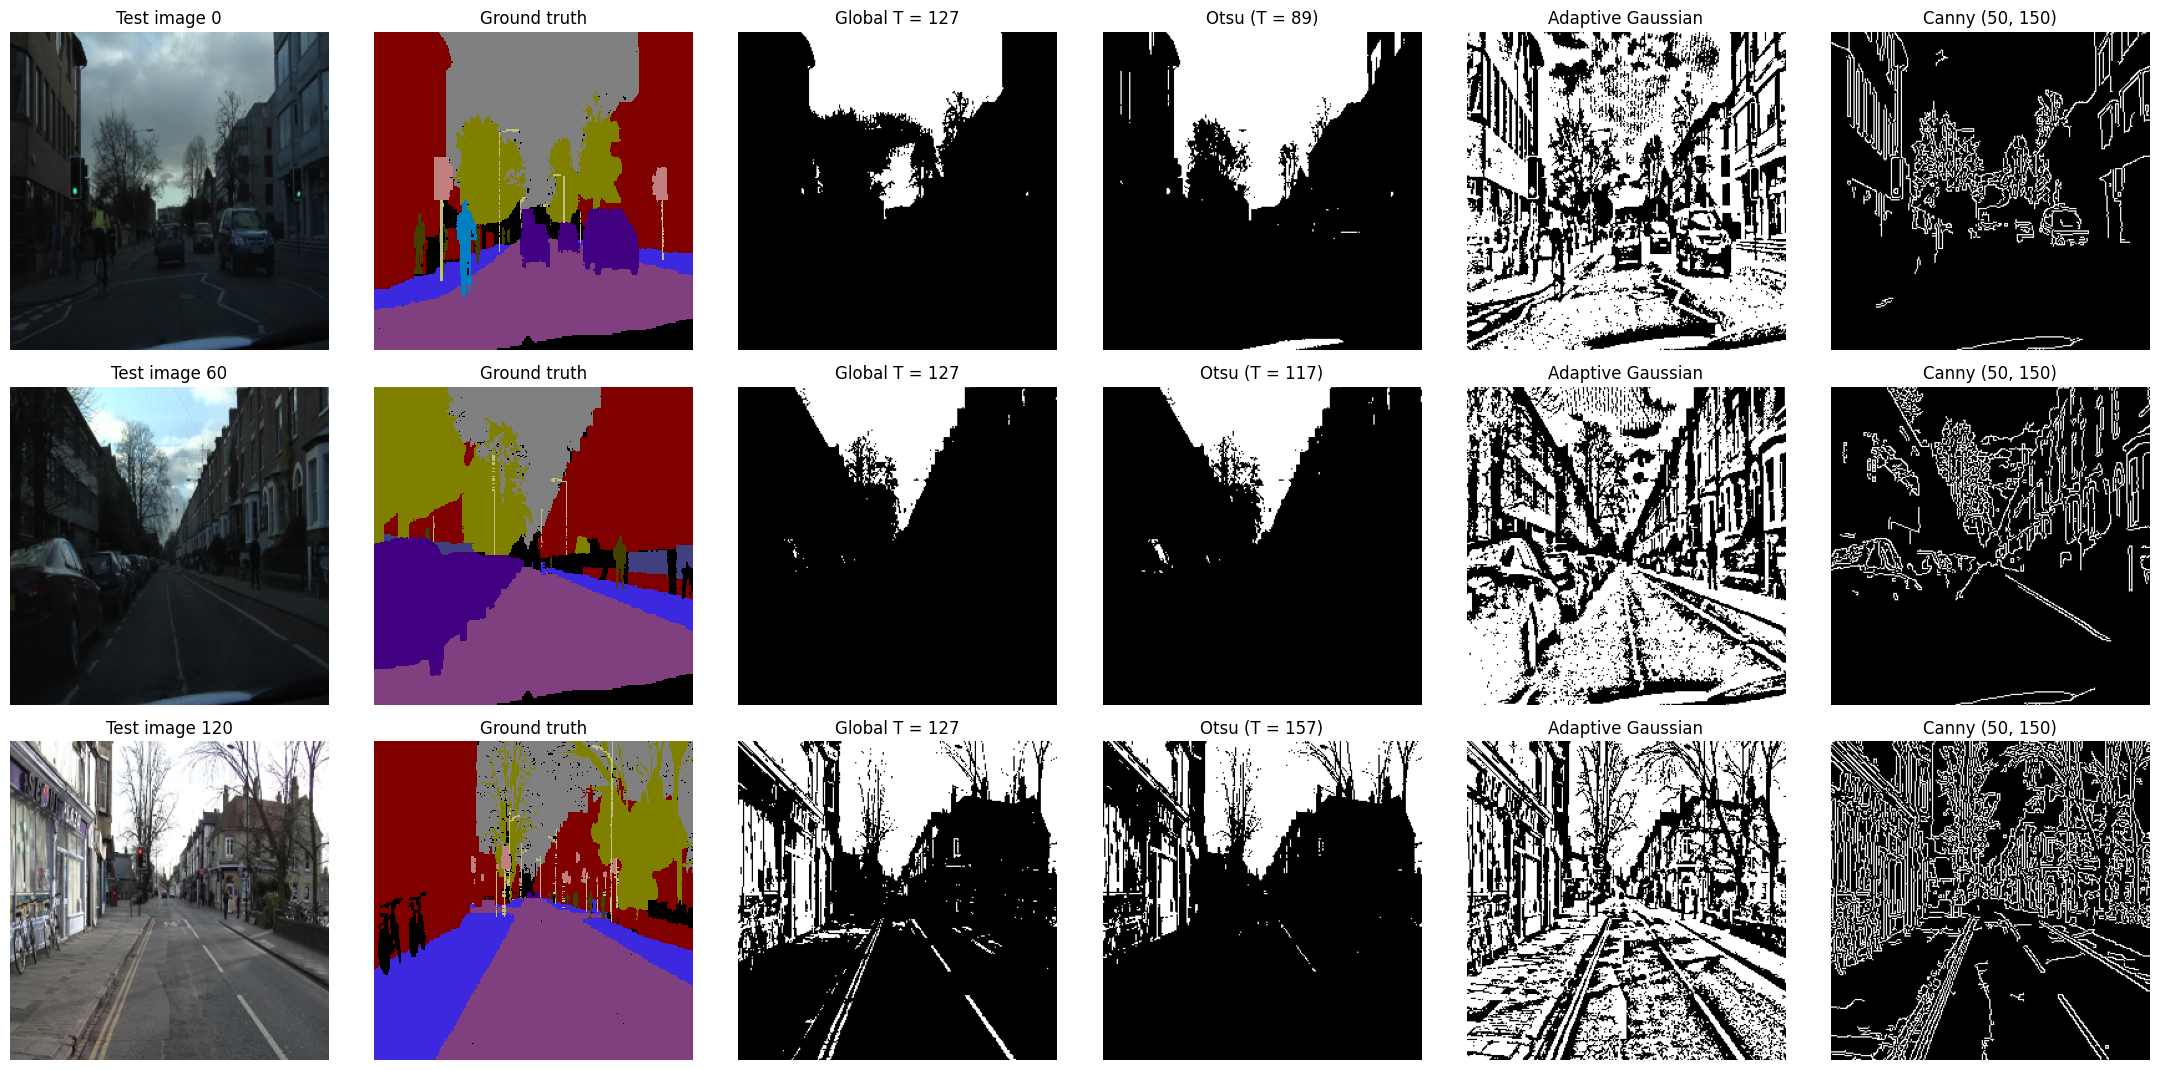

In [ ]:
example_ids = [0, 60, 120]   # 3 test images
fig, axes = plt.subplots(len(example_ids), 6, figsize=(22, 3.6 * len(example_ids)))

for r, idx in enumerate(example_ids):
    img, mask = load_pair(df_test.iloc[idx])
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # The 4 methods of Lecture 08
    _, th_global = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
    t_otsu, th_otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    th_adapt = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 2)
    edges = cv2.Canny(gray, 50, 150)

    axes[r, 0].imshow(img); axes[r, 0].set_title(f"Test image {idx}")
    show_mask(axes[r, 1], mask, "Ground truth")
    axes[r, 2].imshow(th_global, cmap="gray"); axes[r, 2].set_title("Global T = 127")
    axes[r, 3].imshow(th_otsu, cmap="gray"); axes[r, 3].set_title(f"Otsu (T = {t_otsu:.0f})")
    axes[r, 4].imshow(th_adapt, cmap="gray"); axes[r, 4].set_title("Adaptive Gaussian")
    axes[r, 5].imshow(edges, cmap="gray"); axes[r, 5].set_title("Canny (50, 150)")
    for ax in axes[r]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### 2.1 Measuring it: Otsu as a road detector
To put a number on it, we use Otsu to separate "road" from "not road" on all test images. Otsu does not know which side is the road, so we keep the better side for each image, which is generous to Otsu.

In [ ]:
ROAD = CLASS_NAMES.index("Road")
otsu_ious = []

for i in range(len(df_test)):
    img, mask = load_pair(df_test.iloc[i])
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, th = cv2.threshold(gray, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    valid = mask != VOID_CLASS              # ignore void pixels
    gt_road = (mask == ROAD) & valid

    # Try both sides (bright = road, dark = road) and keep the best IoU
    best = 0.0
    for pred_road in (th == 1, th == 0):
        pred_road = pred_road & valid
        inter = np.logical_and(pred_road, gt_road).sum()
        union = np.logical_or(pred_road, gt_road).sum()
        best = max(best, inter / max(union, 1))
    otsu_ious.append(best)

print(f"Otsu as a road detector: mean road IoU on test = {np.mean(otsu_ious):.3f}")

Otsu as a road detector: mean road IoU on test = 0.345


**What we learn from Part A:** the Otsu threshold changes for every image (89, 117, 157) because the lighting changes, and thresholds mostly separate the sky from the rest. Canny finds edges, but they are not closed regions. Even when helped, Otsu only reaches a road IoU of 0.345.
So one value per pixel is not enough: we need to look at **regions** and use **several types of information** (colour, texture, position).

## 3. Part B, step 1 – Superpixels (SLIC)
Classifying 65,536 pixels one by one using only their colour would be slow and noisy. We first group neighbouring pixels of similar colour into superpixels with SLIC (a k-means on colour + position).
A superpixel contains enough pixels to compute a reliable average colour or texture. The downside: an object thinner than a superpixel (a pole) gets merged with its neighbour.
The figure shows the trade-off: more superpixels keep small details, fewer superpixels contain more information each. The number is chosen in section 5.

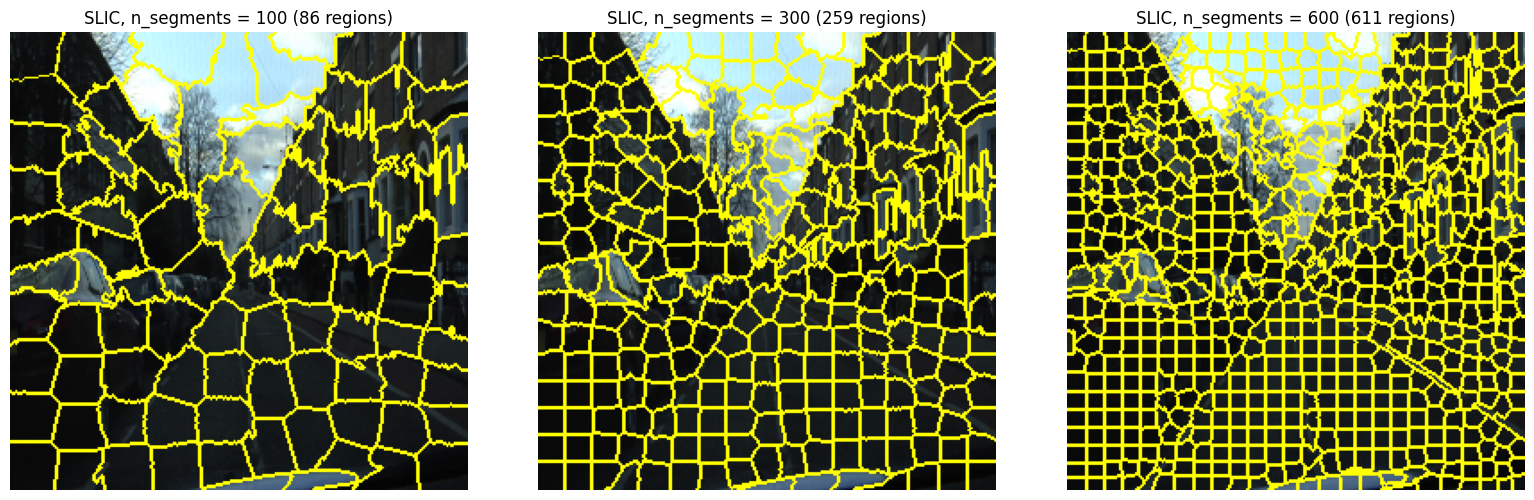

In [ ]:
img, mask = load_pair(df_test.iloc[60])
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Same image with 3 different numbers of superpixels
for ax, n in zip(axes, [100, 300, 600]):
    seg = slic(img, n_segments=n, compactness=10, start_label=0)
    ax.imshow(mark_boundaries(img, seg, color=(1, 1, 0)))   # yellow borders
    ax.set_title(f"SLIC, n_segments = {n} ({seg.max() + 1} regions)")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Part B, step 2 – Describing each superpixel (hand-crafted features)
A U-Net learns by itself what to look at. Here, we decide it: each superpixel is described by 42 numbers.
- **Colour (18):** mean and std in RGB, HSV and Lab. HSV and Lab separate brightness from colour, which helps when the same road is in the shade or in the sun.
- **Texture (10):** LBP histogram. Smooth areas (road, sky) and textured areas (trees, bricks) give different codes.
- **Gradients (9):** edge strength and edge direction (HOG-style). Buildings and poles have vertical edges.
- **Position (5):** where the superpixel is in the image and its size. The sky is always at the top and the road at the bottom.

To train, each superpixel gets the most frequent ground-truth class of its pixels (void ignored).

In [ ]:
FEATURE_NAMES = (
    [f"{stat}_{ch}" for ch in ["R", "G", "B", "H", "S", "V", "L", "a", "b"] for stat in ["mean", "std"]]
    + [f"LBP_{k}" for k in range(10)]
    + ["grad_mag"] + [f"grad_ori_{k}" for k in range(8)]
    + ["x_mean", "y_mean", "y_top", "y_bottom", "area"]
)

# x and y coordinates of every pixel, between 0 and 1
YY, XX = np.mgrid[0:IMAGE_SIZE, 0:IMAGE_SIZE] / IMAGE_SIZE

def superpixel_features(img, seg):
    """Returns a (number of superpixels, 42) feature matrix for one image."""
    n = seg.max() + 1
    flat = seg.ravel()
    counts = np.bincount(flat, minlength=n).astype(np.float64)   # pixels per superpixel

    def region_mean(values):
        # Mean of 'values' inside each superpixel
        return np.bincount(flat, weights=values.ravel(), minlength=n) / counts

    feats = []

    # 1. Colour: mean and std in RGB, HSV and Lab (scaled to [0, 1])
    rgb = img.astype(np.float64) / 255.0
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float64) / [180.0, 255.0, 255.0]
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float64) / 255.0
    for space in (rgb, hsv, lab):
        for c in range(3):
            m = region_mean(space[..., c])
            m2 = region_mean(space[..., c] ** 2)
            feats += [m, np.sqrt(np.maximum(m2 - m ** 2, 0))]   # mean, std

    # 2. Texture: share of each uniform LBP code (0..9) in the superpixel
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    for k in range(10):
        feats.append(region_mean((lbp == k).astype(np.float64)))

    # 3. Gradients (HOG-style): mean magnitude + orientation histogram weighted by magnitude
    g = gray.astype(np.float64) / 255.0
    gx = cv2.Sobel(g, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(g, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    ori_bin = np.minimum((np.mod(np.arctan2(gy, gx), np.pi) / np.pi * 8).astype(int), 7)   # 8 directions
    mag_sum = np.bincount(flat, weights=mag.ravel(), minlength=n)
    feats.append(mag_sum / counts)
    for k in range(8):
        feats.append(np.bincount(flat, weights=(mag * (ori_bin == k)).ravel(), minlength=n) / (mag_sum + 1e-6))

    # 4. Position and size
    y_top = np.full(n, np.inf)
    y_bottom = np.full(n, -np.inf)
    np.minimum.at(y_top, flat, YY.ravel())
    np.maximum.at(y_bottom, flat, YY.ravel())
    feats += [region_mean(XX), region_mean(YY), y_top, y_bottom, counts / flat.size]

    return np.stack(feats, axis=1).astype(np.float32)


def superpixel_labels(seg, mask):
    """Majority ground-truth class of each superpixel (void excluded), -1 if only void."""
    n = seg.max() + 1
    hist = np.bincount(seg.ravel() * NUM_CLASSES + mask.ravel().astype(np.int64),
                       minlength=n * NUM_CLASSES).reshape(n, NUM_CLASSES)
    hist[:, VOID_CLASS] = 0
    labels = hist.argmax(axis=1)
    labels[hist.sum(axis=1) == 0] = -1
    return labels


def extract_split(df, n_segments, compactness=10):
    """SLIC + features + labels for every image of a split."""
    X_list, y_list, segs, masks = [], [], [], []
    for i in range(len(df)):
        img, mask = load_pair(df.iloc[i])
        seg = slic(img, n_segments=n_segments, compactness=compactness, start_label=0)
        X_list.append(superpixel_features(img, seg))
        y_list.append(superpixel_labels(seg, mask))
        segs.append(seg)
        masks.append(mask)
    return X_list, y_list, segs, masks


# Quick test on one image
sample_img, _ = load_pair(df_train.iloc[0])
sample_seg = slic(sample_img, n_segments=300, compactness=10, start_label=0)
sample_X = superpixel_features(sample_img, sample_seg)
print(f"One image -> {sample_X.shape[0]} superpixels x {sample_X.shape[1]} features")

One image -> 258 superpixels x 42 features


## 5. Part B, step 3 – Random Forest and design choices
**Classifier:** a Random Forest of 100 decision trees. Each tree is trained on a random sample with a random subset of features, and the trees vote. It works well without fine tuning, runs fast on CPU and tells us which features matter (section 7.4).

**Metric:** same as notebook 03. The class predicted for a superpixel is copied to all its pixels, then mIoU is computed per pixel (void ignored). mIoU gives the same weight to every class, unlike pixel accuracy.

**Design choices (slide 7):** we test 4 settings on the **validation set only**, the test set is used once at the end.
- 200 or 400 superpixels per image.
- `class_weight` None or "balanced". CamVid is very imbalanced, and without weights the forest is pushed to always predict road, sky or building.

**Oracle:** each superpixel gets its true class. It is the best score possible with these superpixels.

In [ ]:
def update_confusion(confusion, pred, mask):
    """Adds the pixels of one image to the confusion matrix (void ignored)."""
    valid = mask != VOID_CLASS
    idx = mask[valid].astype(np.int64) * NUM_CLASSES + pred[valid].astype(np.int64)
    confusion += np.bincount(idx, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)
    return confusion

def miou_from_confusion(confusion):
    """IoU per class and mean IoU (void excluded), same formula as notebook 03."""
    intersection = np.diag(confusion).astype(np.float64)
    union = confusion.sum(0) + confusion.sum(1) - intersection
    iou = intersection / np.maximum(union, 1)
    present = union[:VOID_CLASS] > 0
    return iou[:VOID_CLASS][present].mean(), iou

def predict_masks(model, X_list, segs):
    """Predicts the class of every superpixel and paints it on all its pixels."""
    return [model.predict(X)[seg].astype(np.uint8) for X, seg in zip(X_list, segs)]

def evaluate(pred_masks, masks):
    """mIoU, IoU per class, pixel accuracy and confusion matrix over a whole split."""
    confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    for p, m in zip(pred_masks, masks):
        confusion = update_confusion(confusion, p, m)
    miou, iou = miou_from_confusion(confusion)
    pixel_acc = np.trace(confusion) / confusion.sum()
    return miou, iou, pixel_acc, confusion

def stack_training(X_list, y_list):
    """Puts all superpixels of all images in one table (void-only superpixels removed)."""
    X = np.concatenate(X_list)
    y = np.concatenate(y_list)
    keep = y >= 0
    return X[keep], y[keep]

def make_forest(class_weight):
    return RandomForestClassifier(n_estimators=100, min_samples_leaf=2, max_features="sqrt",
                                  class_weight=class_weight, n_jobs=-1, random_state=42)


results = []
cache = {}   # keeps the extracted features so we do not compute them twice

for n_seg in [200, 400]:
    t0 = time.time()
    tr = extract_split(df_train, n_seg)
    va = extract_split(df_val, n_seg)
    cache[n_seg] = (tr, va)
    X_tr, y_tr = stack_training(tr[0], tr[1])

    # Oracle: every superpixel takes its true majority class
    oracle_masks = [np.where(lab >= 0, lab, 0)[seg].astype(np.uint8) for lab, seg in zip(va[1], va[2])]
    oracle_miou = evaluate(oracle_masks, va[3])[0]
    print(f"n_segments={n_seg}: {len(y_tr)} training superpixels ({time.time() - t0:.0f} s), "
          f"oracle val mIoU = {oracle_miou:.3f}")

    for cw in [None, "balanced"]:
        rf = make_forest(cw).fit(X_tr, y_tr)
        miou, _, acc, _ = evaluate(predict_masks(rf, va[0], va[2]), va[3])
        results.append({"n_segments": n_seg, "class_weight": str(cw), "Val mIoU": round(miou, 4),
                        "Val pixel acc": round(acc, 4), "Oracle val mIoU": round(oracle_miou, 4)})
        print(f"   class_weight={str(cw):<9} -> val mIoU = {miou:.4f} | pixel acc = {acc:.4f}")

df_results = pd.DataFrame(results)
df_results

n_segments=200: 54103 training superpixels (72 s), oracle val mIoU = 0.614
   class_weight=None      -> val mIoU = 0.3576 | pixel acc = 0.7978
   class_weight=balanced  -> val mIoU = 0.3918 | pixel acc = 0.8045
n_segments=400: 116170 training superpixels (74 s), oracle val mIoU = 0.685
   class_weight=None      -> val mIoU = 0.3704 | pixel acc = 0.8003
   class_weight=balanced  -> val mIoU = 0.4015 | pixel acc = 0.8081


,n_segments,class_weight,Val mIoU,Val pixel acc,Oracle val mIoU
0,200,None,0.3576,0.7978,0.6145
1,200,balanced,0.3918,0.8045,0.6145
2,400,None,0.3704,0.8003,0.6854
3,400,balanced,0.4015,0.8081,0.6854


**Result of the design choices:** "balanced" always wins (+3 mIoU points) while pixel accuracy stays around 0.80. This shows why pixel accuracy is misleading here: it is dominated by the large classes.
400 superpixels are better than 200 (oracle 0.69 vs 0.61). Our best validation mIoU (0.40) is far below the oracle (0.69): the main limit is the hand-crafted features, not the superpixels.
**Chosen setting: 400 superpixels, balanced class weights.**

## 6. Final training and test evaluation
We train the Random Forest with the chosen setting and evaluate it once on the 233 test images. These are the numbers for the comparison table (slide 8).

In [ ]:
# Best setting on validation
best = df_results.sort_values("Val mIoU", ascending=False).iloc[0]
BEST_N_SEG = int(best["n_segments"])
BEST_CW = None if best["class_weight"] == "None" else best["class_weight"]
print(f"Chosen setting: n_segments = {BEST_N_SEG}, class_weight = {BEST_CW}")

# Train on the training superpixels (already computed in section 5)
tr, _ = cache[BEST_N_SEG]
X_tr, y_tr = stack_training(tr[0], tr[1])
t0 = time.time()
final_rf = make_forest(BEST_CW).fit(X_tr, y_tr)
print(f"Random Forest trained on {len(y_tr)} superpixels in {time.time() - t0:.0f} s")

# Test: SLIC + features on the test images, then prediction
te = extract_split(df_test, BEST_N_SEG)
test_pred_masks = predict_masks(final_rf, te[0], te[2])
test_masks = te[3]
test_miou, test_iou, test_acc, test_confusion = evaluate(test_pred_masks, test_masks)

print(f"\nTest mIoU (void class excluded): {test_miou:.4f}")
print(f"Test pixel accuracy:             {test_acc:.4f}")

Chosen setting: n_segments = 400, class_weight = balanced
Random Forest trained on 116170 superpixels in 115 s

Test mIoU (void class excluded): 0.3333
Test pixel accuracy:             0.7572


## 7. Results
### 7.1 IoU per class
Which classes the method handles well and which ones it misses.

,Class,Test IoU
0,Sky,0.851
1,Building,0.630
2,Pole,0.004
3,Road,0.741
4,Pavement,0.218
5,Tree,0.475
6,SignSymbol,0.028
7,Fence,0.048
8,Car,0.443
9,Pedestrian,0.150


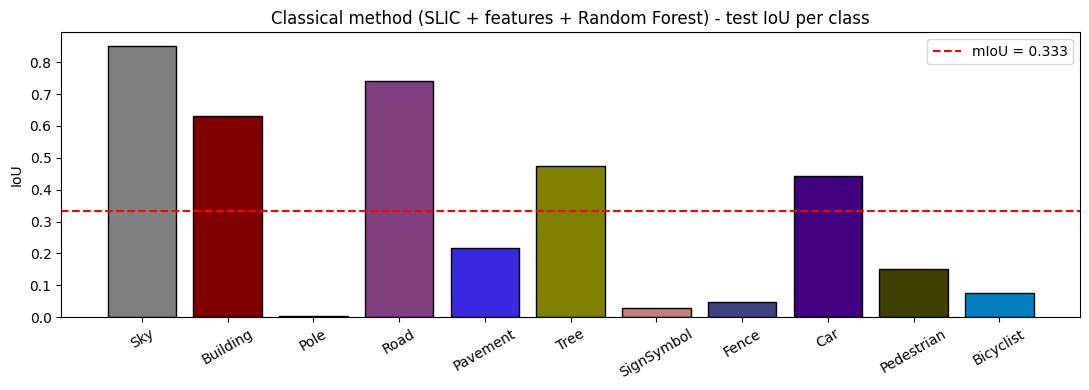

In [ ]:
df_iou = pd.DataFrame({"Class": CLASS_NAMES[:VOID_CLASS], "Test IoU": np.round(test_iou[:VOID_CLASS], 3)})
display(df_iou)

plt.figure(figsize=(11, 4))
plt.bar(df_iou["Class"], df_iou["Test IoU"], color=CLASS_COLORS[:VOID_CLASS], edgecolor="black")
plt.axhline(test_miou, color="red", linestyle="--", label=f"mIoU = {test_miou:.3f}")
plt.ylabel("IoU")
plt.title("Classical method (SLIC + features + Random Forest) - test IoU per class")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

### 7.2 Confusion matrix (slide 8)
Each row is a true class and shows what its pixels were predicted as. The diagonal is the correct part. Same format as notebook 03, so the two matrices can be put side by side.

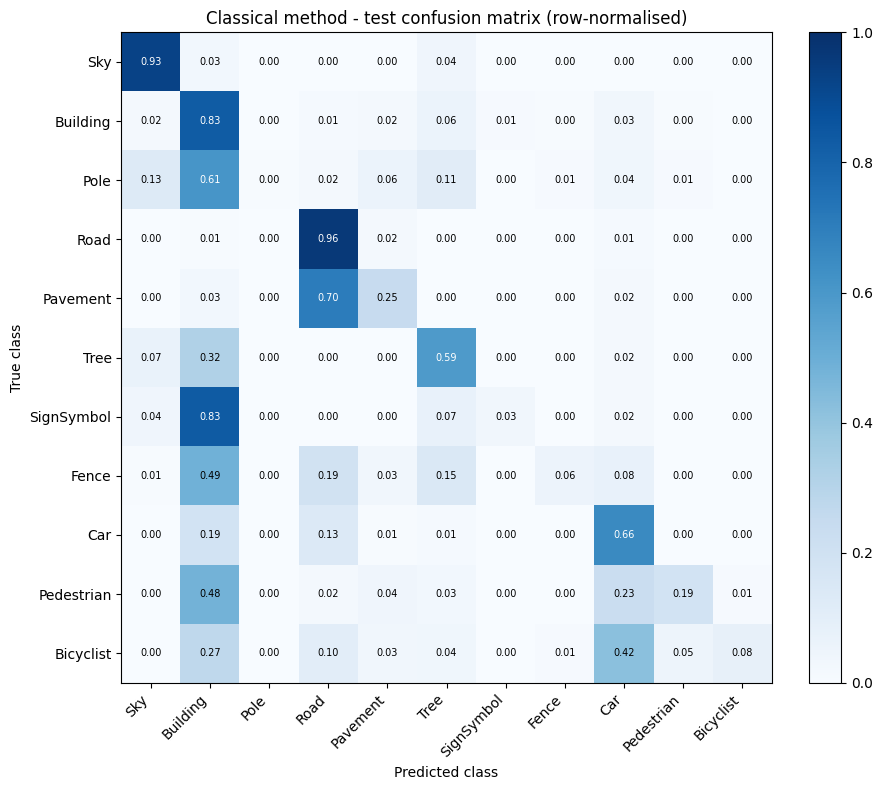

In [ ]:
cm = test_confusion[:VOID_CLASS, :VOID_CLASS].astype(np.float64)
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)   # each row sums to 1

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(VOID_CLASS)); ax.set_xticklabels(CLASS_NAMES[:VOID_CLASS], rotation=45, ha="right")
ax.set_yticks(range(VOID_CLASS)); ax.set_yticklabels(CLASS_NAMES[:VOID_CLASS])
for i in range(VOID_CLASS):
    for j in range(VOID_CLASS):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title("Classical method - test confusion matrix (row-normalised)")
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.show()

**Test results:** mIoU = 0.333, better than the U-Net trained from scratch (0.24) but below the pretrained U-Net (0.47).
- **What works:** sky (0.85), road (0.74) and building (0.63). Large regions with a typical colour, texture and position.
- **Thin objects are lost:** pole (0.004), sign (0.03). 61% of pole pixels and 83% of sign pixels are predicted as building because they are thinner than a superpixel.
- **Building is the default answer:** it also takes 48% of pedestrians and 49% of fences.
- **Pavement is predicted as road (70%):** same colour, texture and position. Telling them apart needs context (the kerb, the neighbouring regions), but our features only look inside each superpixel. A CNN sees more context at each layer.
- **Bicyclists are predicted as cars (42%):** our features do not describe shape.

### 7.3 Best and worst test images (slides 9-10)
We compute the mIoU of each test image and show the 3 best and the 3 worst. The U-Net predictions should be shown on the **same** image numbers, to compare both methods on the same cases.

Best test images : [np.int64(62), np.int64(8), np.int64(200)] [0.516 0.472 0.468]
Worst test images: [np.int64(149), np.int64(177), np.int64(182)] [0.197 0.206 0.216]


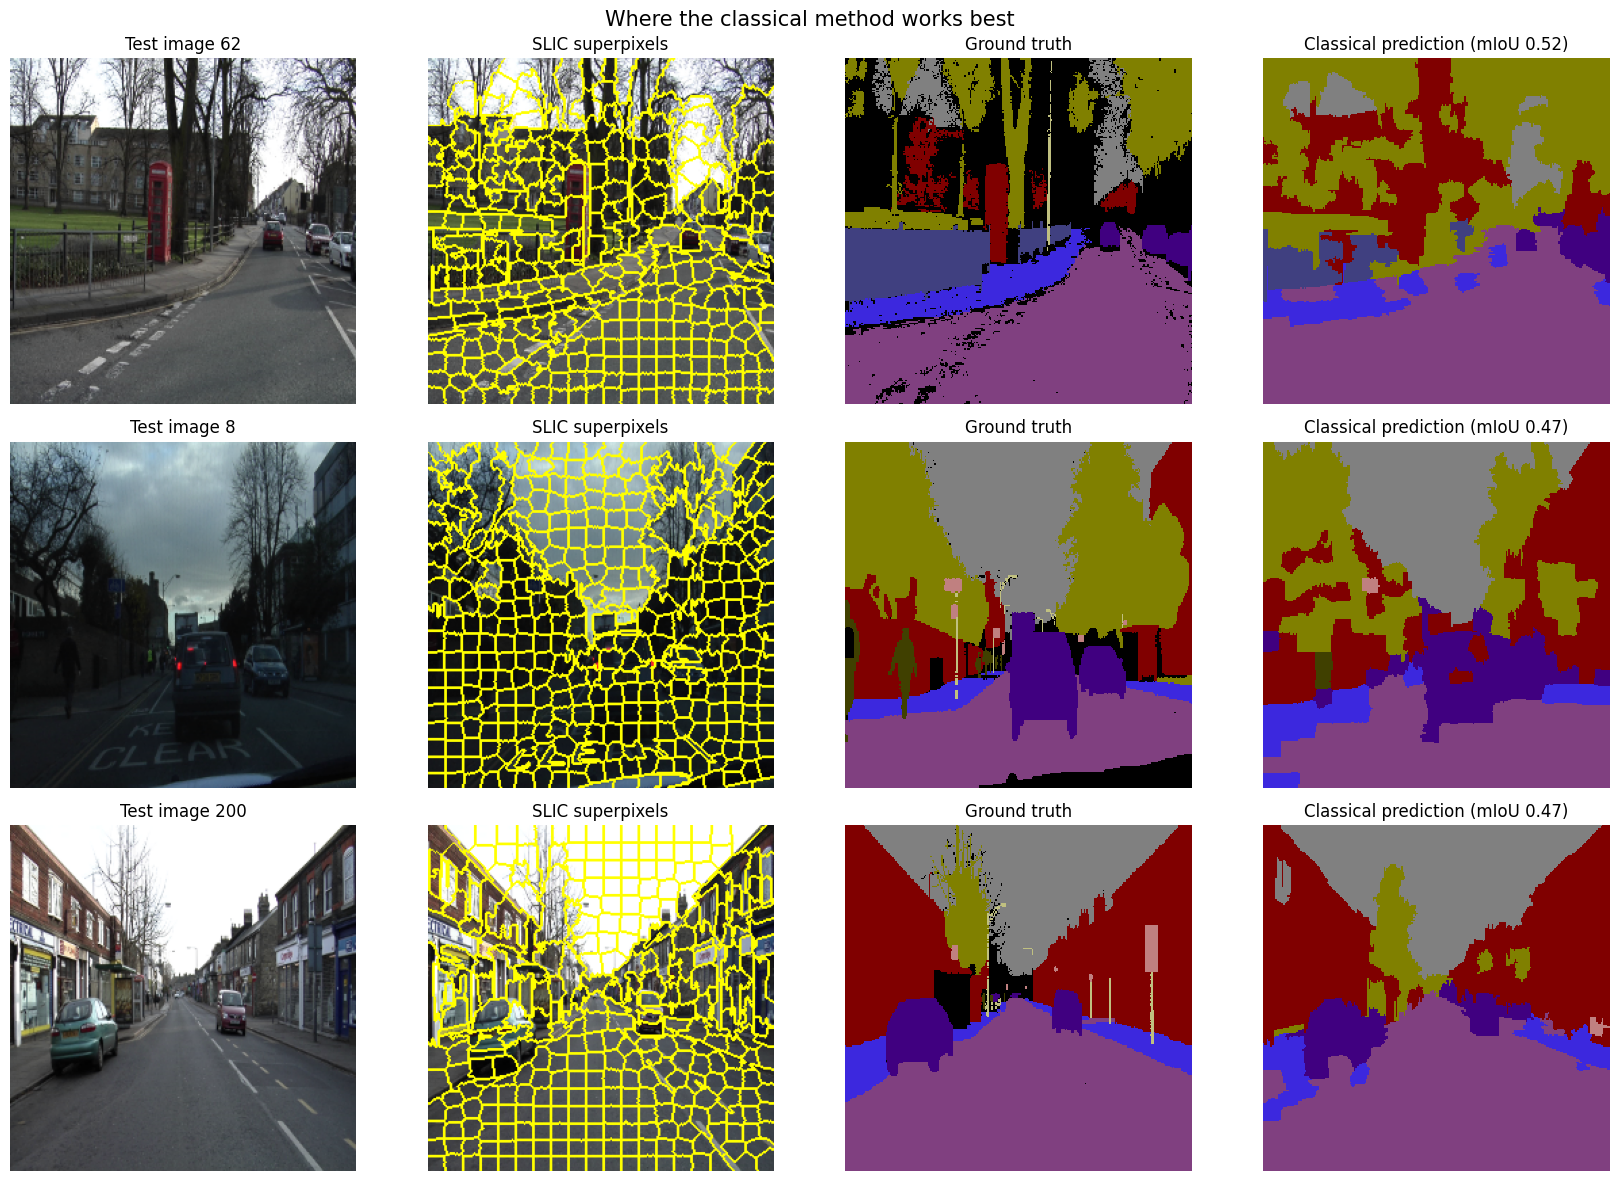

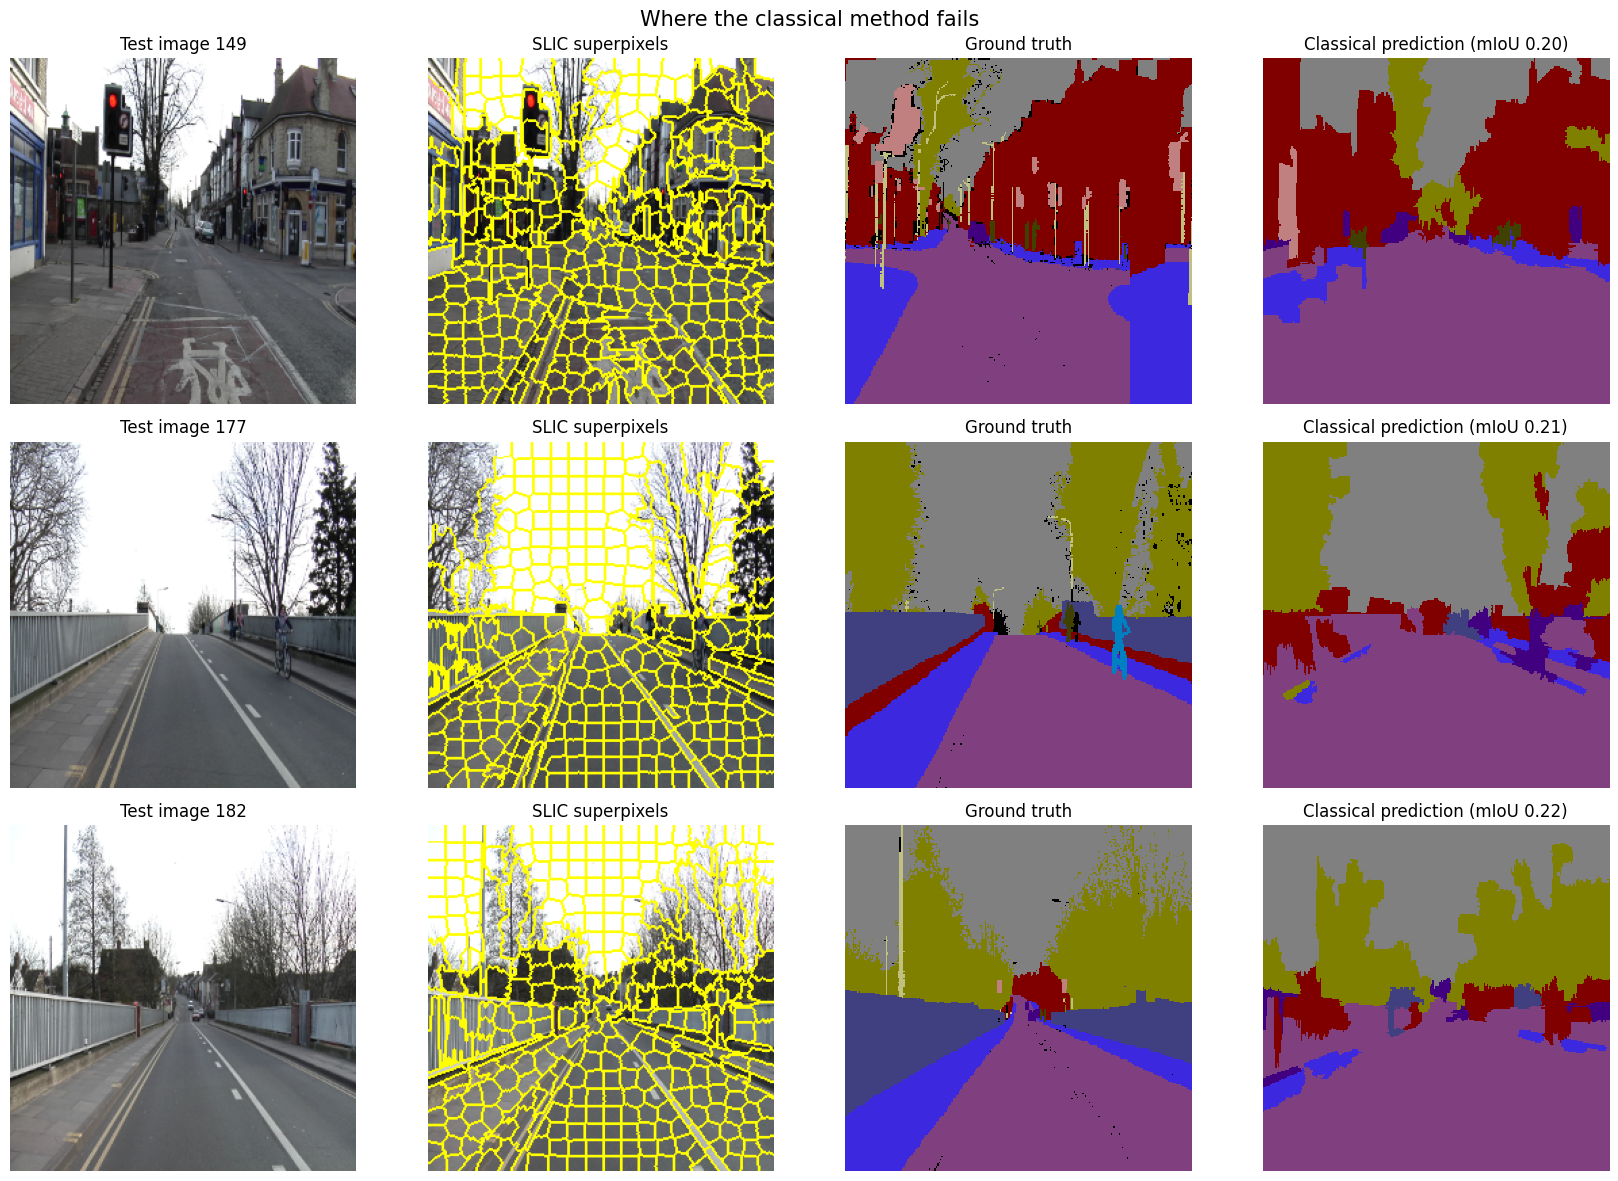

In [ ]:
# mIoU of every test image
per_image = []
for p, m in zip(test_pred_masks, test_masks):
    conf = update_confusion(np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64), p, m)
    per_image.append(miou_from_confusion(conf)[0])
per_image = np.array(per_image)

order = np.argsort(per_image)
best_ids, worst_ids = order[::-1][:3], order[:3]
print("Best test images :", list(best_ids), np.round(per_image[best_ids], 3))
print("Worst test images:", list(worst_ids), np.round(per_image[worst_ids], 3))

def show_examples(ids, title):
    """Image | superpixels | ground truth | classical prediction."""
    fig, axes = plt.subplots(len(ids), 4, figsize=(17, 4 * len(ids)))
    for r, idx in enumerate(ids):
        img, _ = load_pair(df_test.iloc[idx])
        axes[r, 0].imshow(img); axes[r, 0].set_title(f"Test image {idx}"); axes[r, 0].axis("off")
        axes[r, 1].imshow(mark_boundaries(img, te[2][idx], color=(1, 1, 0)))
        axes[r, 1].set_title("SLIC superpixels"); axes[r, 1].axis("off")
        show_mask(axes[r, 2], test_masks[idx], "Ground truth")
        show_mask(axes[r, 3], test_pred_masks[idx], f"Classical prediction (mIoU {per_image[idx]:.2f})")
    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

show_examples(best_ids, "Where the classical method works best")
show_examples(worst_ids, "Where the classical method fails")

### 7.4 Which features does the Random Forest use?
Shows what the method relies on, useful for the limitations slide.

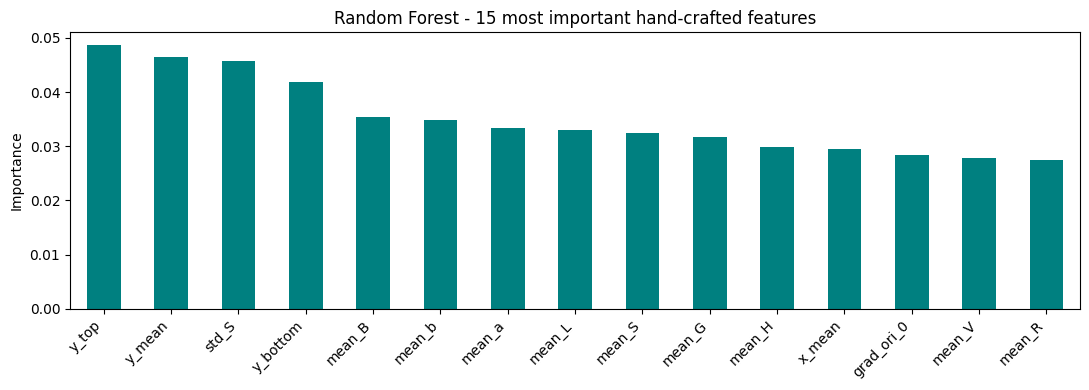

Colour                 total importance = 0.47
Texture (LBP)          total importance = 0.17
Gradients (HOG-style)  total importance = 0.18
Position / shape       total importance = 0.18


In [ ]:
importances = pd.Series(final_rf.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)

plt.figure(figsize=(11, 4))
importances.head(15).plot(kind="bar", color="teal")
plt.ylabel("Importance")
plt.title("Random Forest - 15 most important hand-crafted features")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Total importance of each group of features
groups = {"Colour": FEATURE_NAMES[:18], "Texture (LBP)": FEATURE_NAMES[18:28],
          "Gradients (HOG-style)": FEATURE_NAMES[28:37], "Position / shape": FEATURE_NAMES[37:]}
for g, names in groups.items():
    print(f"{g:<22} total importance = {importances[names].sum():.2f}")

**Failure cases (images 149, 177, 182):** pavement becomes road on all three images. On the two bridge scenes (177, 182), the large metal fence is predicted as building or road, because it is grey like the road and fences are rare in the training set. Poles, the traffic light and the bicyclist are lost. Sky and trees are still correct, even with a white overexposed sky.

**Feature importance:** colour has the largest total (0.47), but only because it has 18 features. The 4 most important single features are vertical positions and saturation std. The method partly learned "sky at the top, road at the bottom", so it would fail with an unusual camera angle.

## 8. Save the predictions
The 233 predicted masks are saved in the same order as the test set, to put them next to the U-Net predictions on slides 9-10.

In [ ]:
np.savez_compressed("classical_test_predictions.npz",
                    preds=np.stack(test_pred_masks),
                    image_names=df_test["image_path"].map(lambda p: Path(p).name).values,
                    per_image_miou=per_image)
print("Saved classical_test_predictions.npz")
print(f"Summary -> test mIoU = {test_miou:.4f} | pixel accuracy = {test_acc:.4f} "
      f"| n_segments = {BEST_N_SEG} | class_weight = {BEST_CW}")

Saved classical_test_predictions.npz
Summary -> test mIoU = 0.3333 | pixel accuracy = 0.7572 | n_segments = 400 | class_weight = balanced
